# Inpainting detector gaps with the pretrained model

This notebook downloads the released weights from the Hugging Face Hub and fills the detector gaps of a projection stack, in two ways:

* **projection mode** (`inpaint`): every projection is inpainted on its own;
* **sinogram mode** (`inpaint_sinograms`): the gap columns are filled in the sinograms of all detector rows, the gap rows in the projections.

To be self-contained, the notebook simulates a small projection stack of a random object on a detector with real gap widths (7 and 17 px). The true values in the gaps are known, so all methods can be compared with the ground truth. The last section shows how to apply the model to your own data.

Requirements: run the notebook in a clone of this repository, or install the package with `pip install "git+https://github.com/J-3TO/detectorGapRemoval_Pix2Pix"`; plus matplotlib. A GPU is optional; on a CPU the inpainting takes a few minutes.

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from gap_pix2pix import detector_gap_mask, inpaint, inpaint_sinograms, interpolate_gaps, load_generator

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Load the pretrained generator

`"hf"` downloads the generator weights (69 MB) from the Hugging Face Hub on first use and caches them; a path to a local `.pth` file works as well.

In [2]:
WEIGHTS = "hf"   # or the path of a downloaded pix2pix_projections_sinograms_generator.pth

generator = load_generator(WEIGHTS, device=device)
print(f"generator loaded: {sum(p.numel() for p in generator.parameters()):,} parameters")

generator loaded: 17,262,401 parameters


## 2. A simulated projection stack

The object is a cylinder containing thousands of small inclusions (3D Gaussian blobs), denser or less dense than their surroundings, rotated over 180°. Projections are the transmission $T = e^{-\int \mu\,\mathrm{d}l}$ with Poisson noise, like flat-field corrected data. The detector consists of 2 × 3 modules of 120 × 100 pixels with gaps of 7 (rows) and 17 (columns) pixels, the gap widths of a Pilatus3 2M.

projection stack: (180, 247, 334) | gap pixels: 12.7%


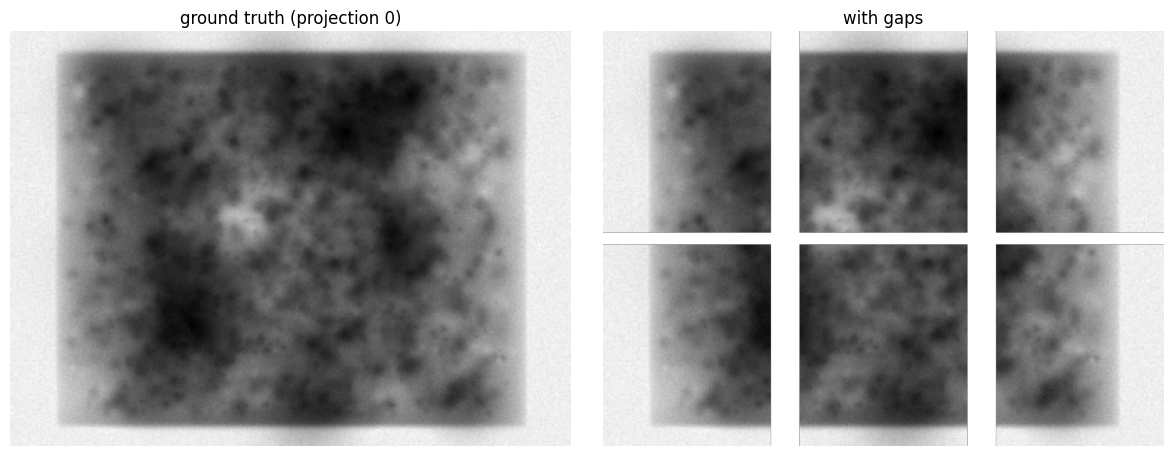

In [3]:
def simulate_projections(n_angles=180, height=247, width=334, n_blobs=3000, counts=5000, seed=0):
    # Parallel-beam projections (angles, height, width) of a cylinder with many small inclusions,
    # as transmission with Poisson noise. The line integral of a 3D Gaussian blob is a 2D Gaussian
    # on the detector, that of the cylinder 2 * mu * sqrt(R^2 - u^2).
    rng = np.random.default_rng(seed)
    radius, mu_body = 0.42 * width, np.log(2) / (0.84 * width)   # ~50 % transmission at the centre
    r = 0.95 * radius * np.sqrt(rng.uniform(0, 1, n_blobs))      # inclusions inside the cylinder
    phi = rng.uniform(0, 2 * np.pi, n_blobs)
    x, y = r * np.cos(phi), r * np.sin(phi)
    z = rng.uniform(0.08, 0.92, n_blobs) * height
    sigma = np.where(rng.uniform(size=n_blobs) < 0.97,
                     np.exp(rng.uniform(np.log(0.8), np.log(5.0), n_blobs)),    # mostly small
                     rng.uniform(8.0, 20.0, n_blobs))                          # a few larger ones
    density = rng.uniform(-0.6, 1.0, n_blobs) * 0.04 / sigma ** 0.5          # denser or lighter
    weight = density * np.sqrt(2 * np.pi) * sigma                 # line integral through the blob centre
    rows, cols = np.arange(height), np.arange(width) - width / 2
    g_z = np.exp(-0.5 * ((rows[None] - z[:, None]) / sigma[:, None]) ** 2) * weight[:, None]
    in_height = 1 / (1 + np.exp(-(rows - 0.05 * height))) / (1 + np.exp(rows - 0.95 * height))
    body = 2 * mu_body * np.sqrt(np.clip(radius ** 2 - cols ** 2, 0, None))
    stack = np.empty((n_angles, height, width), dtype=np.float32)
    for k, theta in enumerate(np.linspace(0, np.pi, n_angles, endpoint=False)):
        u = x * np.cos(theta) + y * np.sin(theta)                # inclusion positions on the detector
        g_u = np.exp(-0.5 * ((cols[None] - u[:, None]) / sigma[:, None]) ** 2)
        line_integral = np.clip(in_height[:, None] * body[None, :] + g_z.T @ g_u, 0, None)
        stack[k] = rng.poisson(counts * np.exp(-line_integral)) / counts
    return stack


truth = simulate_projections()
gap_mask = detector_gap_mask(module_size=(120, 100), gap_size=(7, 17), grid=(2, 3))   # True = gap
measured = np.where(gap_mask, np.nan, truth)                 # what the detector records
print("projection stack:", truth.shape, "| gap pixels:", f"{gap_mask.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(truth[0], cmap="gray"); ax[0].set_title("ground truth (projection 0)")
ax[1].imshow(measured[0], cmap="gray"); ax[1].set_title("with gaps")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Inpainting

`inpaint` passes the images batch by batch to `generator.predict`, which z-scores each image with the mean and standard deviation of its valid pixels, interpolates the gaps linearly, runs the U-Net, and undoes the normalization; valid pixels are returned unchanged. The values in the gaps of the input are ignored (here they are NaN).

`inpaint_sinograms` needs all projections of the scan in their acquisition order: it inpaints the gap columns in the sinograms first, where the object's trajectories continue across the gap, and then the gap rows in the projections.

In [4]:
linear = interpolate_gaps(measured, gap_mask)                                   # baseline
pix2pix_proj = inpaint(measured, gap_mask, generator, batch_size=8, progress=True)
pix2pix_sino = inpaint_sinograms(measured, gap_mask, generator, batch_size=8, progress=True)

180/180
sinograms: rows 247/247
180/180


## 4. Results

A crop around a crossing of a gap row and a gap column, for one projection, inpainted in projection mode. The dashed lines mark the gaps.

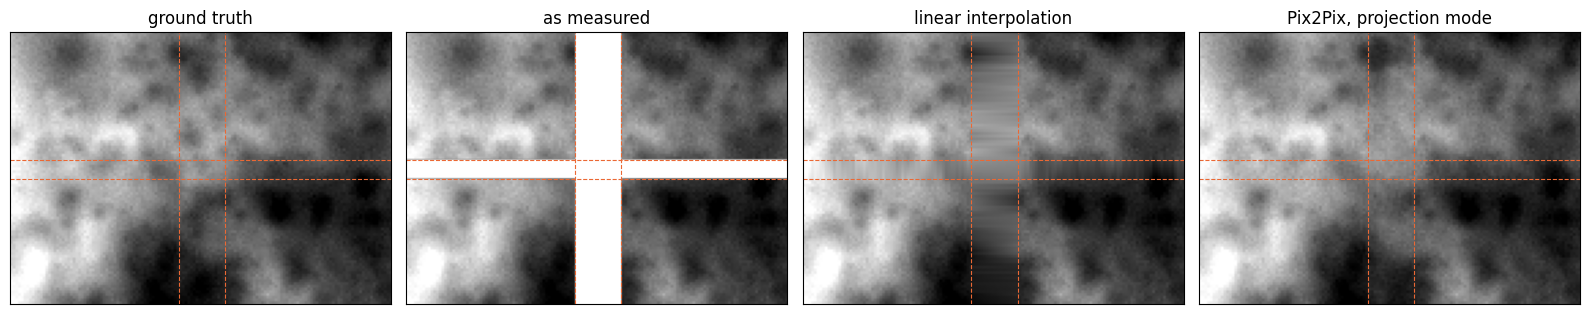

In [5]:
k = 30                                     # projection to show
gap_rows, gap_cols = np.flatnonzero(gap_mask.all(1)), np.flatnonzero(gap_mask.all(0))
cy, cx = gap_rows.mean().astype(int), gap_cols[:17].mean().astype(int)   # first crossing
crop = (slice(cy - 50, cy + 50), slice(cx - 70, cx + 70))
vmin, vmax = np.percentile(truth[k][crop], [1, 99])
panels = {"ground truth": truth, "as measured": measured, "linear interpolation": linear,
          "Pix2Pix, projection mode": pix2pix_proj}

fig, ax = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.4))
for a, (name, img) in zip(ax, panels.items()):
    a.imshow(img[k][crop], cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(name)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
    for r0 in (gap_rows[0], gap_rows[-1] + 1):
        a.axhline(r0 - crop[0].start - 0.5, color="#eb6834", lw=0.8, ls="--")
    for c0 in (gap_cols[0], gap_cols[16] + 1):
        a.axvline(c0 - crop[1].start - 0.5, color="#eb6834", lw=0.8, ls="--")
plt.tight_layout(); plt.show()

The sinogram of one detector row: a gap column is a stripe across all angles, while the inclusions trace sinusoidal trajectories through it. In sinogram mode, the generator sees these trajectories on both sides of the gap and continues them. Because every detector row is inpainted separately, faint horizontal streaks can appear in the gap columns of the projections.

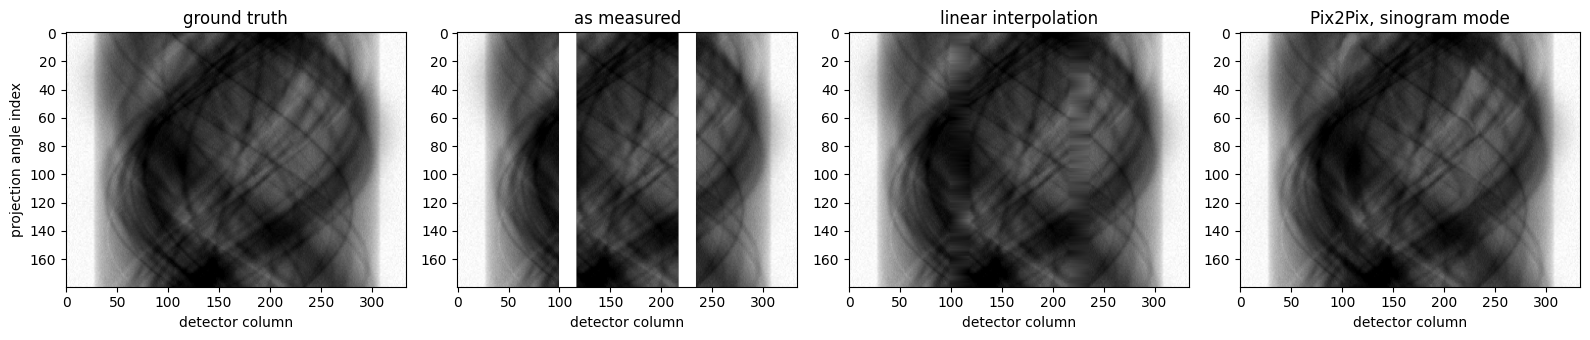

In [6]:
row = 60                                   # a detector row that is not a gap row
sino_panels = {"ground truth": truth, "as measured": measured, "linear interpolation": linear,
               "Pix2Pix, sinogram mode": pix2pix_sino}
vmin, vmax = np.percentile(truth[:, row], [1, 99])
fig, ax = plt.subplots(1, len(sino_panels), figsize=(4 * len(sino_panels), 3.5))
for a, (name, stack) in zip(ax, sino_panels.items()):
    a.imshow(stack[:, row], cmap="gray", vmin=vmin, vmax=vmax, aspect="auto")
    a.set_title(name); a.set_xlabel("detector column")
ax[0].set_ylabel("projection angle index")
plt.tight_layout(); plt.show()

## 5. Your own data

For your own measurements, load the flat-field corrected projections and the gap mask of your detector (True = gap; the gaps must be complete rows and columns). For a Pilatus3 2M:

```python
from gap_pix2pix import pilatus3_2m_gap_mask

projections = np.load("projections.npy")      # (angles, 1475, 1679), flat-field corrected
mask = pilatus3_2m_gap_mask()                 # (1475, 1679), True = gap

filled = inpaint(projections, mask, generator, batch_size=4, progress=True)
# or, with all projection angles of the scan in acquisition order:
filled = inpaint_sinograms(projections, mask, generator, batch_size=4, progress=True)
```

For other detectors, `detector_gap_mask(module_size, gap_size, grid)` builds the mask of a regular module grid.